### Name : Muhammad Saad
### Reg.No: SP24-BSE-081
### Course : Machine Learning Fundamentals

# Titanic Survival Prediction with a Decision Tree

Goal: predict whether a passenger survived, using `train.csv`, then score the model and generate predictions for `test.csv`.

**Steps:** load data -> explore -> feature engineering -> tune a decision tree -> evaluate -> predict test set.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV,StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
DATA = "/home/saadm/University/6th Semester/ML-Sir Qaiser Habib/Lab/titanic/"
train = pd.read_csv(DATA + "train.csv")
test = pd.read_csv(DATA + "test.csv")
gender = pd.read_csv(DATA + "gender_submission.csv")
print(train.shape, test.shape)
train.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Explore the data

In [3]:
print(train.isna().sum()[lambda s: s > 0], "\n")
print(f"Overall survival rate: {train['Survived'].mean():.1%}")

Age         177
Cabin       687
Embarked      2
dtype: int64 

Overall survival rate: 38.4%


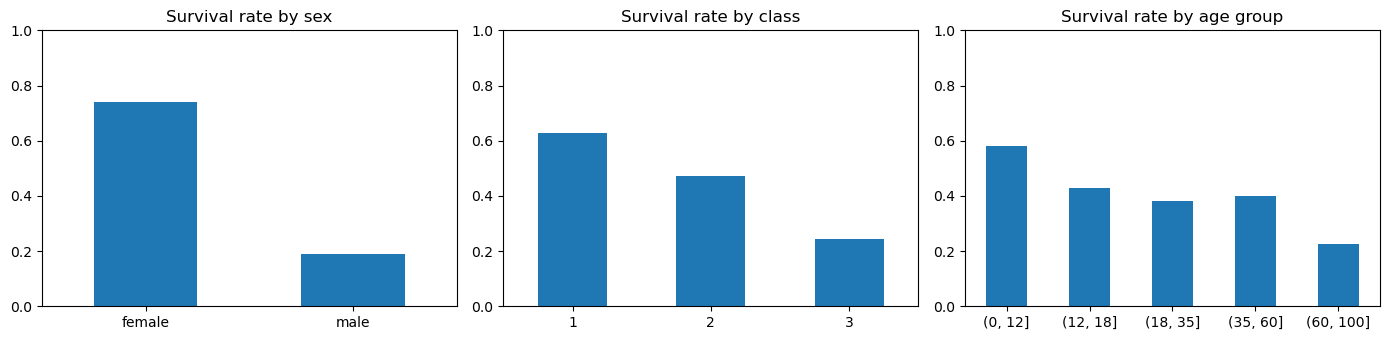

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
train.groupby("Sex")["Survived"].mean().plot.bar(ax=ax[0], title="Survival rate by sex", rot=0)
train.groupby("Pclass")["Survived"].mean().plot.bar(ax=ax[1], title="Survival rate by class", rot=0)
train.groupby(pd.cut(train["Age"], [0, 12, 18, 35, 60, 100]), observed=True)["Survived"].mean() \
     .plot.bar(ax=ax[2], title="Survival rate by age group", rot=0)
for a in ax: a.set_ylim(0, 1); a.set_xlabel("")
plt.tight_layout(); plt.show()

## 2. Feature engineering

- **Title** extracted from `Name` (Mr / Mrs / Miss / Master / Rare) and used to fill missing ages with the median age for that title
- **FamilySize**, **IsAlone**, **HasCabin**
- Missing `Embarked` and `Fare` are filled using values from the *training* set only, so nothing leaks from the test set

In [5]:
def prepare(df, ref):
    df = df.copy()
    df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
    df["Age"] = df["Age"].fillna(ref["Age"].median())
    df["Fare"] = df["Fare"].fillna(ref["Fare"].median())
    df["Embarked"] = df["Embarked"].fillna(ref["Embarked"].mode()[0])
    df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    return pd.get_dummies(df, columns=["Embarked", "Title"])

tr, te = prepare(train, train), prepare(test, train)
features = ["Pclass", "Sex", "Age", "Fare", "FamilySize", "IsAlone", "HasCabin"] + \
           sorted(c for c in tr.columns if c.startswith(("Embarked_", "Title_")))
for c in features:
    if c not in te: te[c] = 0

X, y = tr[features].astype(float), train["Survived"]
X_test = te[features].astype(float)
print(len(features), "features:", features)

15 features: ['Pclass', 'Sex', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


## 3. Train / validation split and hyperparameter tuning

In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Reference: an unrestricted tree overfits
deep = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)
print(f"Unpruned tree -> train {deep.score(X_tr, y_tr):.3f} | validation {deep.score(X_val, y_val):.3f}")

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth": [2, 3, 4, 5, 6, 7], "min_samples_leaf": [1, 3, 5, 10, 20], "criterion": ["gini", "entropy"]},
    cv=5, scoring="accuracy").fit(X_tr, y_tr)
model = grid.best_estimator_
print("Best params:", grid.best_params_)

Unpruned tree -> train 0.987 | validation 0.788
Best params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}


## 4. Evaluate the model

Train accuracy:         0.831
Validation accuracy:    0.832
5-fold CV (train.csv):  0.822

              precision    recall  f1-score   support

        Died       0.84      0.90      0.87       110
    Survived       0.82      0.72      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



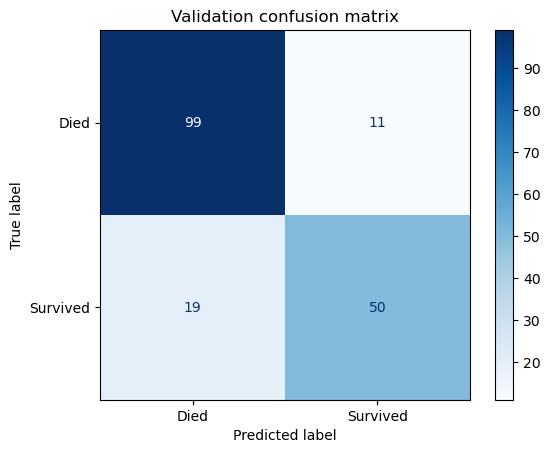

In [7]:
pred = model.predict(X_val)
print(f"Train accuracy:         {model.score(X_tr, y_tr):.3f}")
print(f"Validation accuracy:    {accuracy_score(y_val, pred):.3f}")
print(f"5-fold CV (train.csv):  {cross_val_score(model, X, y, cv=5).mean():.3f}\n")
print(classification_report(y_val, pred, target_names=["Died", "Survived"]))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred), display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title("Validation confusion matrix"); plt.show()

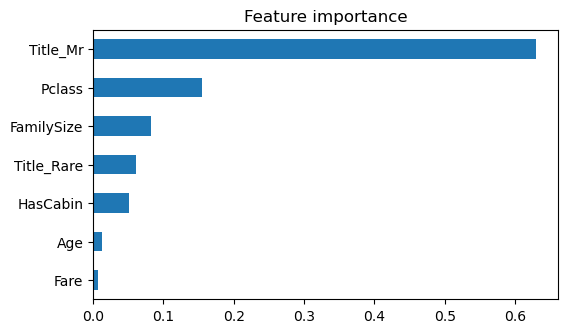

In [8]:
imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp[imp > 0].plot.barh(title="Feature importance", figsize=(6, 3.5)); plt.show()

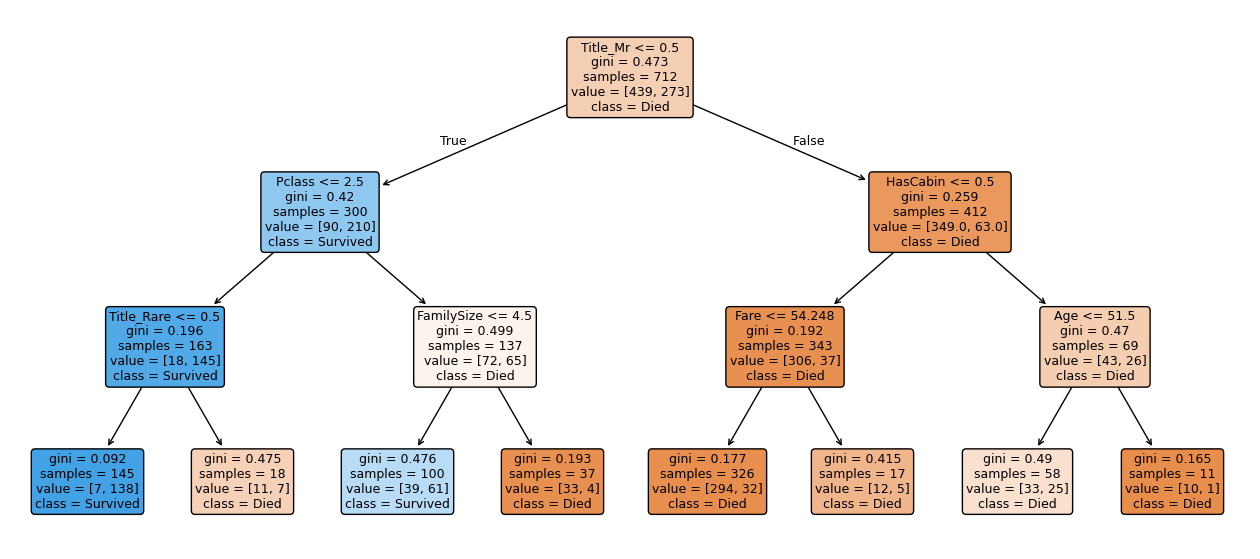

|--- Title_Mr <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Title_Rare <= 0.50
|   |   |   |--- class: 1
|   |   |--- Title_Rare >  0.50
|   |   |   |--- class: 0
|   |--- Pclass >  2.50
|   |   |--- FamilySize <= 4.50
|   |   |   |--- class: 1
|   |   |--- FamilySize >  4.50
|   |   |   |--- class: 0
|--- Title_Mr >  0.50
|   |--- HasCabin <= 0.50
|   |   |--- Fare <= 54.25
|   |   |   |--- class: 0
|   |   |--- Fare >  54.25
|   |   |   |--- class: 0
|   |--- HasCabin >  0.50
|   |   |--- Age <= 51.50
|   |   |   |--- class: 0
|   |   |--- Age >  51.50
|   |   |   |--- class: 0



In [9]:
plt.figure(figsize=(16, 7))
plot_tree(model, feature_names=features, class_names=["Died", "Survived"], filled=True, rounded=True, fontsize=9)
plt.show()
print(export_text(model, feature_names=features))

## 5. Predict the test set

The final model is refit on **all** of `train.csv` with the tuned settings. `test.csv` has no labels, so its true accuracy can only be obtained by submitting to Kaggle. Agreement with `gender_submission.csv` is shown for reference only (it is a baseline, not ground truth).

In [10]:
final = DecisionTreeClassifier(random_state=42, **grid.best_params_).fit(X, y)
sub = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": final.predict(X_test)})
sub.to_csv("submission.csv", index=False)
print(f"Saved submission.csv ({len(sub)} rows) | predicted survival rate: {sub['Survived'].mean():.1%}")
print(f"Agreement with gender_submission baseline: {(sub['Survived'] == gender['Survived']).mean():.1%}")
sub.head()

Saved submission.csv (418 rows) | predicted survival rate: 41.4%
Agreement with gender_submission baseline: 92.6%


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


# Car Evaluation: Decision Tree Classifier

Dataset: UCI Car Evaluation (1,728 cars, 6 categorical inputs, no missing values).

**Target.** In this dataset the thing being predicted is `class`, the overall *acceptability* of the car (`unacc`, `acc`, `good`, `vgood`). `safety` is one of the six *input* attributes. The main model below predicts `class` using all six inputs. Section 6 also shows what happens if `safety` itself is used as the target.

In [ ]:

PATH = "/home/saadm/University/6th Semester/ML-Sir Qaiser Habib/Lab/car_evaluation/"
cols = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
df = pd.read_csv(PATH+"car.data", header=None, names=cols)
print(df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

(1728, 7) | missing values: 0


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 1. Explore

In [12]:
print(df["class"].value_counts(), "\n")
print((df["class"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")
for c in cols[:-1]:
    print(f"{c:9s}", sorted(df[c].unique()))

class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64 

class
unacc    70.0 %
acc      22.2 %
good      4.0 %
vgood     3.8 %
Name: proportion, dtype: str
buying    ['high', 'low', 'med', 'vhigh']
maint     ['high', 'low', 'med', 'vhigh']
doors     ['2', '3', '4', '5more']
persons   ['2', '4', 'more']
lug_boot  ['big', 'med', 'small']
safety    ['high', 'low', 'med']


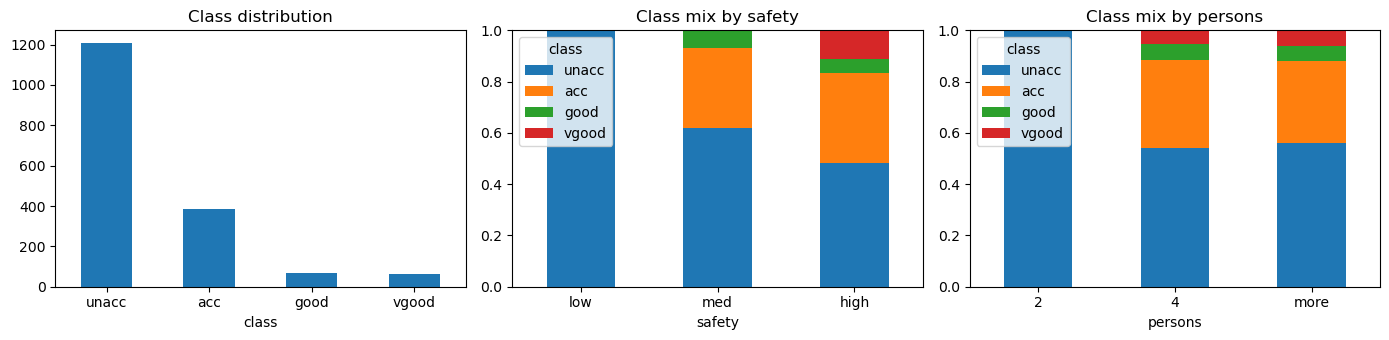

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
order = ["unacc", "acc", "good", "vgood"]
df["class"].value_counts().reindex(order).plot.bar(ax=ax[0], title="Class distribution", rot=0)
pd.crosstab(df["safety"], df["class"], normalize="index")[order].loc[["low", "med", "high"]] \
  .plot.bar(stacked=True, ax=ax[1], title="Class mix by safety", rot=0)
pd.crosstab(df["persons"], df["class"], normalize="index")[order].loc[["2", "4", "more"]] \
  .plot.bar(stacked=True, ax=ax[2], title="Class mix by persons", rot=0)
plt.tight_layout(); plt.show()

## 2. Encode features

All inputs are ordered categories (for example `low < med < high`), so they are mapped to integers in their natural order. A tree only needs the ordering, so this is simpler than one-hot encoding and keeps the tree small and readable.

In [14]:
levels = {
    "buying":   ["low", "med", "high", "vhigh"],
    "maint":    ["low", "med", "high", "vhigh"],
    "doors":    ["2", "3", "4", "5more"],
    "persons":  ["2", "4", "more"],
    "lug_boot": ["small", "med", "big"],
    "safety":   ["low", "med", "high"],
}
features = list(levels)
df[["doors", "persons"]] = df[["doors", "persons"]].astype(str)

enc = OrdinalEncoder(categories=[levels[c] for c in features])
X = pd.DataFrame(enc.fit_transform(df[features]), columns=features)
y = df["class"]
X.head()

,buying,maint,doors,persons,lug_boot,safety
0,3.0,3.0,0.0,0.0,0.0,0.0
1,3.0,3.0,0.0,0.0,0.0,1.0
2,3.0,3.0,0.0,0.0,0.0,2.0
3,3.0,3.0,0.0,0.0,1.0,0.0
4,3.0,3.0,0.0,0.0,1.0,1.0


## 3. Train / test split and tuning

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

deep = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print(f"Unpruned tree -> train {deep.score(X_train, y_train):.3f} | test {deep.score(X_test, y_test):.3f}, depth {deep.get_depth()}, leaves {deep.get_n_leaves()}")

cv = StratifiedKFold(5, shuffle=True, random_state=42)
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"criterion": ["gini", "entropy"], "max_depth": [3, 4, 5, 6, 7, 8, 10, None],
     "min_samples_leaf": [1, 2, 5, 10], "class_weight": [None, "balanced"]},
    cv=cv, scoring="accuracy").fit(X_train, y_train)
model = grid.best_estimator_
print("Best params:", grid.best_params_, "| CV accuracy:", round(grid.best_score_, 3))

(1209, 6) (519, 6)
Unpruned tree -> train 1.000 | test 0.983, depth 12, leaves 72
Best params: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1} | CV accuracy: 0.972


## 4. Evaluate

Train accuracy:     0.997
Test accuracy:      0.985
5-fold CV (all data): 0.979

              precision    recall  f1-score   support

       unacc       0.99      0.99      0.99       363
         acc       0.97      0.96      0.96       115
        good       0.91      1.00      0.95        21
       vgood       1.00      1.00      1.00        20

    accuracy                           0.98       519
   macro avg       0.97      0.99      0.98       519
weighted avg       0.98      0.98      0.98       519



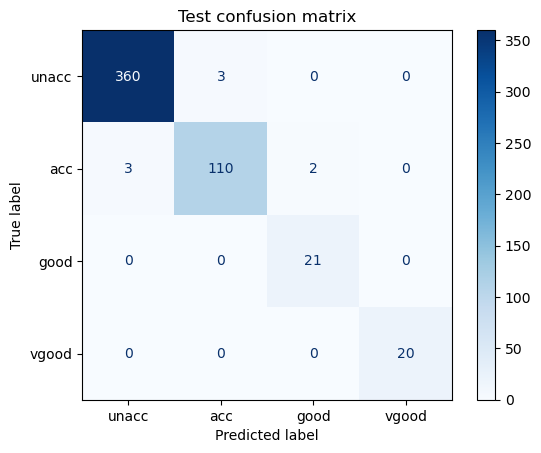

In [16]:
pred = model.predict(X_test)
print(f"Train accuracy:     {model.score(X_train, y_train):.3f}")
print(f"Test accuracy:      {accuracy_score(y_test, pred):.3f}")
print(f"5-fold CV (all data): {cross_val_score(model, X, y, cv=cv).mean():.3f}\n")
labels = ["unacc", "acc", "good", "vgood"]
print(classification_report(y_test, pred, labels=labels, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels), display_labels=labels).plot(cmap="Blues")
plt.title("Test confusion matrix"); plt.show()

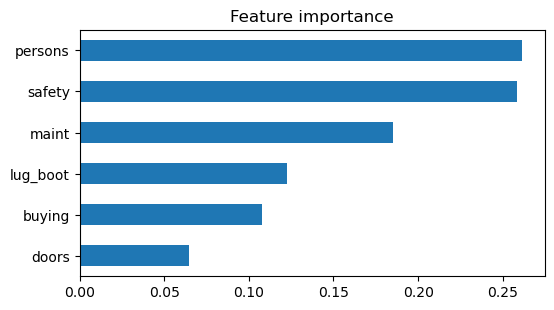

persons     0.262
safety      0.258
maint       0.185
lug_boot    0.123
buying      0.108
doors       0.064
dtype: float64


In [17]:
imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp.plot.barh(title="Feature importance", figsize=(6, 3.2)); plt.show()
print(imp.sort_values(ascending=False).round(3))

## 5. The learned tree

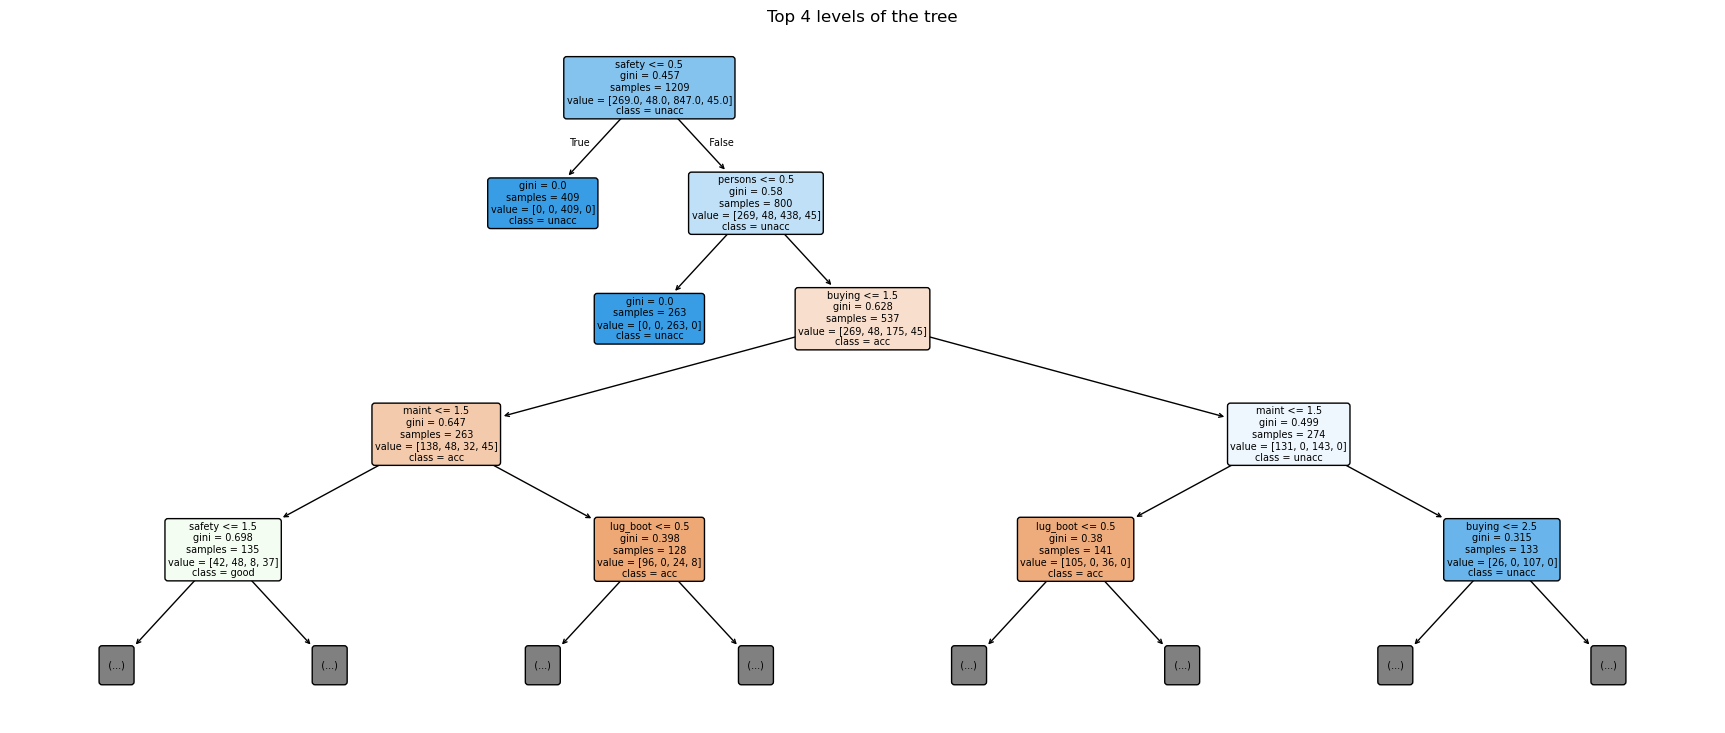

|--- safety <= 0.50
|   |--- class: unacc
|--- safety >  0.50
|   |--- persons <= 0.50
|   |   |--- class: unacc
|   |--- persons >  0.50
|   |   |--- buying <= 1.50
|   |   |   |--- maint <= 1.50
|   |   |   |   |--- safety <= 1.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- safety >  1.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- maint >  1.50
|   |   |   |   |--- lug_boot <= 0.50
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |--- lug_boot >  0.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |--- buying >  1.50
|   |   |   |--- maint <= 1.50
|   |   |   |   |--- lug_boot <= 0.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- lug_boot >  0.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- maint >  1.50
|   |   |   |   |--- buying <= 2.50
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- buying >  2.50
|   |   |   |  

In [18]:
plt.figure(figsize=(22, 9))
plot_tree(model, feature_names=features, class_names=list(model.classes_), filled=True, rounded=True, fontsize=7, max_depth=4)
plt.title("Top 4 levels of the tree"); plt.show()
print(export_text(model, feature_names=features, max_depth=4))

## 6. If `safety` is the target

The question mentions predicting the *safety* of the car. In this dataset `safety` is an input, not the label, so this is a different task: predict `safety` from the other five attributes plus the class. A quick check shows that the other attributes carry almost no information about `safety` (the data is a full grid of attribute combinations), so this version of the task is not meaningful.

In [19]:
def score_safety(feature_cols):
    Xs = X[feature_cols]; ys = df["safety"]
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.3, random_state=42, stratify=ys)
    m = DecisionTreeClassifier(max_depth=5, random_state=42).fit(Xtr, ytr)
    return accuracy_score(yte, m.predict(Xte))

others = [f for f in features if f != "safety"]
cls_code = y.map({"unacc": 0, "acc": 1, "good": 2, "vgood": 3})
X_with_class = X.copy(); X_with_class["class_code"] = cls_code

print(f"Majority-class baseline (3 equal classes): {1/3:.3f}")
print(f"Safety from the 5 other attributes only:   {score_safety(others):.3f}")
Xs = X_with_class[others + ["class_code"]]; ys = df["safety"]
Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.3, random_state=42, stratify=ys)
m = DecisionTreeClassifier(max_depth=5, random_state=42).fit(Xtr, ytr)
print(f"Safety from the other 5 attributes + class: {accuracy_score(yte, m.predict(Xte)):.3f}")

Majority-class baseline (3 equal classes): 0.333
Safety from the 5 other attributes only:   0.191
Safety from the other 5 attributes + class: 0.468
